# Customer Churn Prediction

**Problem:** Losing customers is expensive. If a company can predict which customers are likely to leave, the retention team can contact them early with offers or support.

**Goal:** Build a machine learning model that predicts whether a telecom customer will churn, and find the main factors behind churn.

**Dataset:** Telco Customer Churn (IBM sample dataset, 7,043 customers, 21 columns).

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)

sns.set_style("whitegrid")
df = pd.read_csv("telco.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data cleaning

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# TotalCharges is stored as text because some rows contain blank spaces
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
TotalCharges    11
dtype: int64

Duplicate rows: 0


In [4]:
# Blank TotalCharges belong to brand new customers (tenure = 0), so fill with 0
print(df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]].head())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is only an identifier, so drop it
df = df.drop(columns=["customerID"])

# Convert target to 0/1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df.shape

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN


(7043, 20)

## 3. Exploratory data analysis (EDA)

Overall churn rate: 26.5%


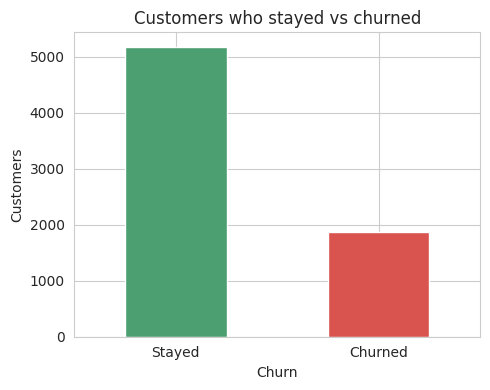

In [5]:
churn_rate = df["Churn"].mean() * 100
print(f"Overall churn rate: {churn_rate:.1f}%")

fig, ax = plt.subplots(figsize=(5, 4))
df["Churn"].value_counts().rename({0: "Stayed", 1: "Churned"}).plot(kind="bar", color=["#4C9F70", "#D9534F"], ax=ax)
ax.set_title("Customers who stayed vs churned")
ax.set_ylabel("Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The data is imbalanced: about 26% of customers churned. Because of this, accuracy alone can mislead, so recall, F1-score and ROC-AUC are used as well.

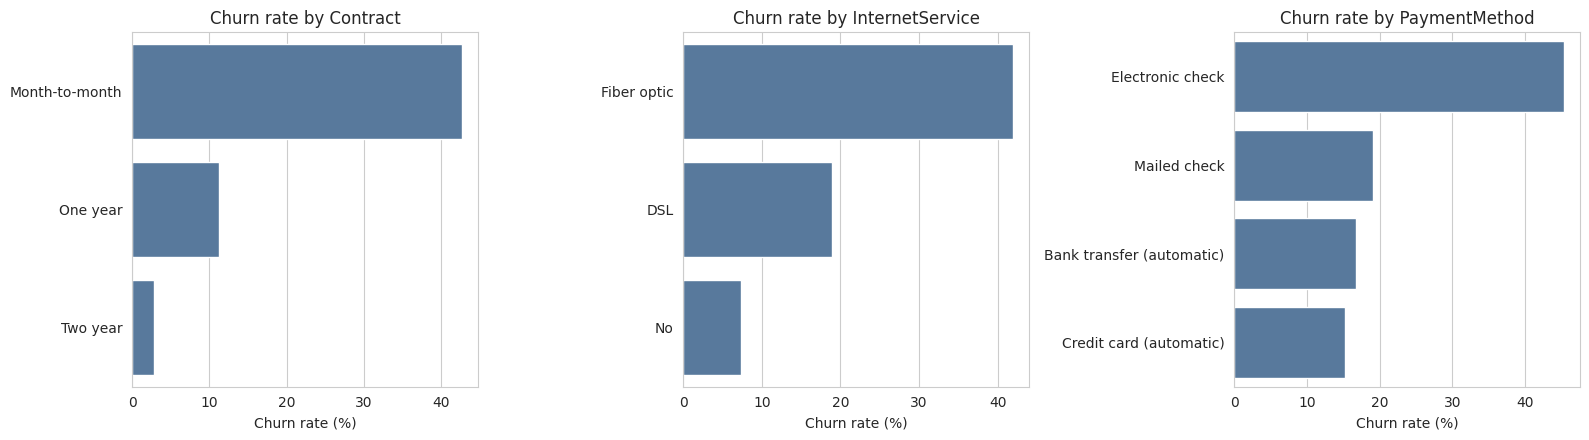

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#4C78A8")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

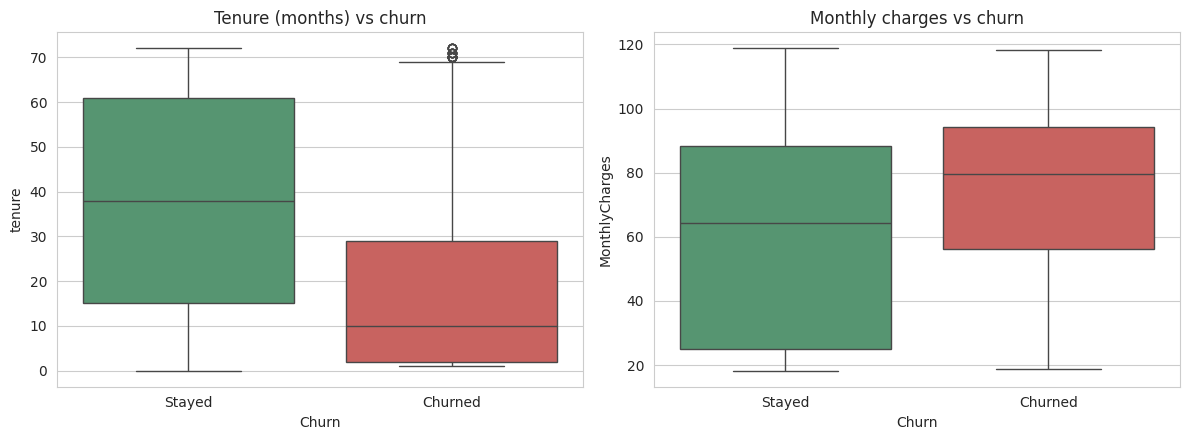

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", legend=False, ax=axes[0], palette=["#4C9F70", "#D9534F"])
axes[0].set_title("Tenure (months) vs churn")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Stayed", "Churned"])
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", legend=False, ax=axes[1], palette=["#4C9F70", "#D9534F"])
axes[1].set_title("Monthly charges vs churn")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Stayed", "Churned"])
plt.tight_layout()
plt.show()

In [8]:
print(df.groupby("Contract")["Churn"].mean().mul(100).round(1))
print()
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

       tenure  MonthlyCharges
Churn                        
0        38.0          64.425
1        10.0          79.650


## 4. Feature engineering and preprocessing

In [9]:
# Simple new features
df["AvgChargesPerMonth"] = np.where(df["tenure"] > 0, df["TotalCharges"] / df["tenure"], df["MonthlyCharges"])
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumServices"] = (df[service_cols] == "Yes").sum(axis=1)

# One-hot encode all text columns
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
y = df["Churn"]
print("Features after encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numeric columns for Logistic Regression
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "AvgChargesPerMonth", "NumServices"]
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])
print("Train:", X_train.shape, "Test:", X_test.shape)

Features after encoding: 32
Train: (5634, 32) Test: (1409, 32)


## 5. Model training

In [10]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42), True),
    "Random Forest": (RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                             class_weight="balanced", random_state=42, n_jobs=-1), False),
}

results, fitted = [], {}
for name, (model, scaled) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    cv = cross_val_score(model, Xtr, y_train, cv=5, scoring="roc_auc").mean()
    fitted[name] = (model, Xte, pred, proba)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV ROC-AUC (5-fold)": cv,
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV ROC-AUC (5-fold)
Model,,,,,,
Logistic Regression,0.740,0.506,0.786,0.616,0.842,0.845
Random Forest,0.761,0.534,0.778,0.633,0.844,0.846


## 6. Model evaluation

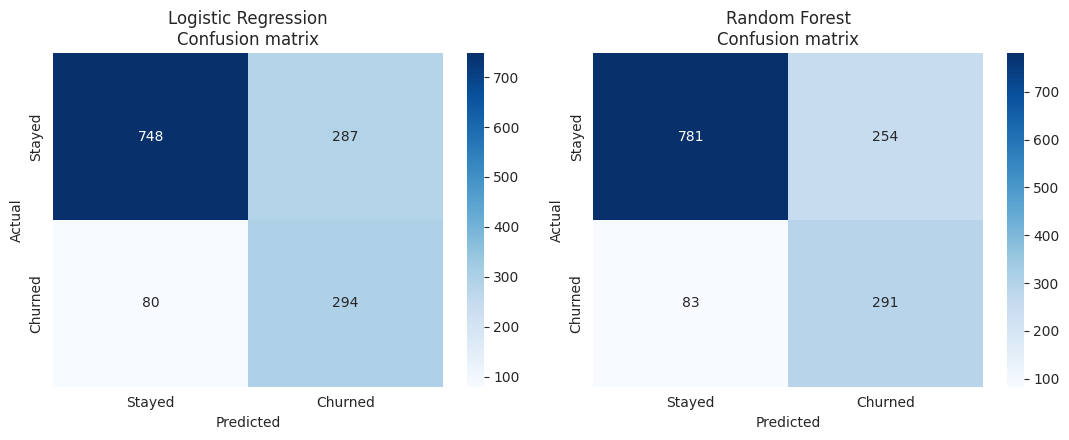

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, (model, Xte, pred, proba)) in zip(axes, fitted.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    ax.set_title(f"{name}\nConfusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

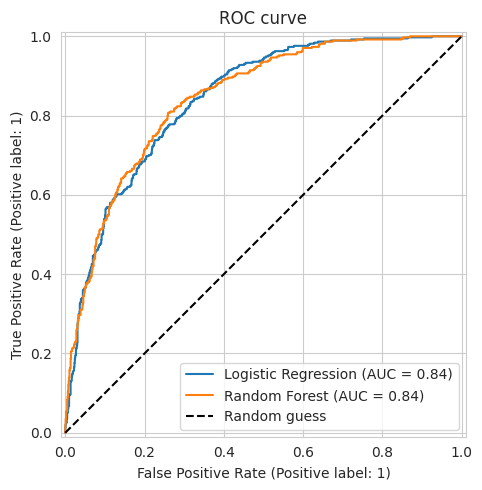

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, (model, Xte, pred, proba) in fitted.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curve")
ax.legend()
plt.tight_layout()
plt.show()

## 7. What drives churn? (feature importance)

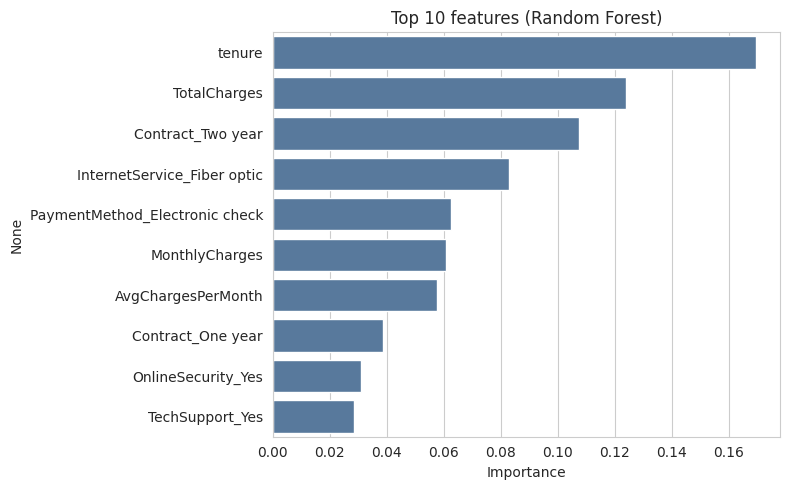

In [13]:
rf = fitted["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#4C78A8", ax=ax)
ax.set_title("Top 10 features (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [14]:
lr = fitted["Logistic Regression"][0]
coef = pd.Series(lr.coef_[0], index=X_train_s.columns).sort_values()
print("Features that REDUCE churn the most:")
print(coef.head(5).round(2))
print("\nFeatures that INCREASE churn the most:")
print(coef.tail(5).round(2))

Features that REDUCE churn the most:
Contract_Two year    -1.41
tenure               -1.15
Contract_One year    -0.72
MonthlyCharges       -0.59
OnlineSecurity_Yes   -0.43
dtype: float64

Features that INCREASE churn the most:
MultipleLines_Yes                 0.33
PaperlessBilling_Yes              0.34
PaymentMethod_Electronic check    0.40
TotalCharges                      0.48
InternetService_Fiber optic       1.24
dtype: float64


## 8. Conclusions and business recommendations

In [15]:
best = results_df["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best)
print(results_df.loc[best])
print("\nChurn rate by contract type (%):")
print(df.groupby("Contract")["Churn"].mean().mul(100).round(1).to_string())

Best model by ROC-AUC: Random Forest
Accuracy               0.761
Precision              0.534
Recall                 0.778
F1-score               0.633
ROC-AUC                0.844
CV ROC-AUC (5-fold)    0.846
Name: Random Forest, dtype: float64

Churn rate by contract type (%):
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8


**Key findings**

- The overall churn rate is **26.5%**.
- **Month-to-month contracts churn at 42.7%**, compared with 11.3% for one-year and 2.8% for two-year contracts.
- **New customers leave first:** the median tenure of churned customers is 10 months, against 38 months for customers who stayed.
- **Fiber optic customers churn at 41.9%** (DSL: 19.0%), and customers paying by **electronic check churn at 45.3%** (automatic payments: about 15-17%).
- Customers **with tech support (15.2%) or online security (14.6%)** churn far less than those without (about 42%).
- The **Random Forest model reached a ROC-AUC of 0.84 and a recall of 78%**, so it catches about 8 out of 10 customers who actually leave.

**Recommendations**

1. Offer discounts or perks to move month-to-month customers onto longer contracts.
2. Build an onboarding and follow-up program for customers in their first 12 months.
3. Review pricing and service quality for fiber optic plans.
4. Encourage automatic payment methods and promote tech support and security add-ons, since both are linked to higher retention.

**Next steps:** tune hyperparameters, try Gradient Boosting or XGBoost, and deploy the model as a Streamlit app.